In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
import pandas as pd
from matplotlib.colors import CenteredNorm

from mg_sampling import PROJECT_DIR
from mg_sampling.density.align import reorder_residue_atoms
from mg_sampling.density.grid import Grid
from mg_sampling.density.utils import QuantileTransformation, indices_to_mask
from mg_sampling.tools import edges_to_range


/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Align two maps

In [3]:
maps = dict()

# maps['New map (2.3 Å)'] = Grid(PROJECT_DIR / 'density/emd_42498.map', file_format='mrc')
# maps['New half-map 1 (2.3 Å)'] = Grid(PROJECT_DIR / 'density/emd_42498_half_map_1.map', file_format='mrc')
# maps['New half-map 2 (2.3 Å)'] = Grid(PROJECT_DIR / 'density/emd_42498_half_map_2.map', file_format='mrc')
# maps['New average half-maps (2.3 Å)'] = (maps['New half-map 1 (2.3 Å)'] + maps['New half-map 2 (2.3 Å)']) / 2
# maps['New map (2.3 Å) unsharp.'] = maps['New map (2.3 Å)'].apply_tempfactor(74.07)

maps["New map (2.2 Å)"] = Grid(PROJECT_DIR / "density/emd_42499.map", file_format="mrc")
maps["New half-map 1 (2.2 Å)"] = Grid(
    PROJECT_DIR / "density/emd_42499_half_map_1.map", file_format="mrc"
)
maps["New half-map 2 (2.2 Å)"] = Grid(
    PROJECT_DIR / "density/emd_42499_half_map_2.map", file_format="mrc"
)
maps["New average half-maps (2.2 Å)"] = (
    maps["New half-map 1 (2.2 Å)"] + maps["New half-map 2 (2.2 Å)"]
) / 2
maps["New map (2.2 Å) unsharp."] = maps["New map (2.2 Å)"].apply_tempfactor(79.23)
maps["New map (2.2 Å) unsharp. Phenix"] = Grid(
    PROJECT_DIR / "density/emd_42499_unsharp_phenix.map", file_format="mrc"
)

maps["Old map (3.14 Å)"] = Grid(
    PROJECT_DIR / "density/emd_31385.map", file_format="mrc"
)

old_map = maps["Old map (3.14 Å)"]
new_map = maps["New map (2.2 Å)"]

In [36]:
u = mda.Universe(PROJECT_DIR / "structures/7EZ0_fixed.pdb")
ag = u.select_atoms("name P")
mda.analysis.rms.RMSD(ag).run()

2025-12-19 19:42:54,695 |     INFO | PDBParser.py:332 | Setting segids from chainIDs because no segids found in the PDB file.
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
2025-12-19 19:42:55,408 |     INFO | universe.py:1897 | The attribute(s) types have already been read from the topology file. The guesser will only guess empty values for this attribute, if any exists. To overwrite it by completely guessed values, you can pass the attribute to the force_guess parameter instead of the to_guess one
2025-12-19 19:42:55,414 |     INFO | base.py:182 | There is no empty types values. Guesser did not guess any new values for types attribute
2025-12-19 19:42:55,423 |     INFO | universe.py:1934 | attribute masses has been guessed successfully.
2025-12-19 19:42:55,559 |     INFO | rms.py:555 | RMS calculatio

KeyboardInterrupt: 

In [4]:
structs = dict()

structs["7ez0 (3.14 Å)"] = mda.Universe(PROJECT_DIR / "structures/7EZ0_fixed.pdb")
structs["9cbu (2.2 Å)"] = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb")
structs["9cbx (2.2 Å)"] = mda.Universe(PROJECT_DIR / "structures/9CBX_fixed.pdb")
# structs['9cbw (2.3 Å)'] = mda.Universe(PROJECT_DIR / 'structures/9CBW_fixed.pdb')
# structs['9cby (2.3 Å)'] = mda.Universe(PROJECT_DIR / 'structures/9CBY_fixed.pdb')

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


In [5]:
df = pd.DataFrame(
    {
        ki: {
            kj: mda.analysis.rms.rmsd(
                reorder_residue_atoms(
                    ui.select_atoms(
                        "nucleic and not type H and not (resid 22 and name P OP1 OP2)"
                    )
                ).positions,
                reorder_residue_atoms(
                    uj.select_atoms(
                        "nucleic and not type H and not (resid 22 and name P OP1 OP2)"
                    )
                ).positions,
                superposition=True,
                center=True,
            )
            for kj, uj in structs.items()
        }
        for ki, ui in structs.items()
    }
)
df.round(2)

,7ez0 (3.14 Å),9cbu (2.2 Å),9cbx (2.2 Å)
7ez0 (3.14 Å),0.00,1.61,1.61
9cbu (2.2 Å),1.61,0.00,0.00
9cbx (2.2 Å),1.61,0.00,0.00


In [6]:
# Align old to new with structures
new_ag = reorder_residue_atoms(
    structs["9cbu (2.2 Å)"].select_atoms(
        "nucleic and not type H and not (resid 22 and name P OP1 OP2)"
    )
)
old_ag = reorder_residue_atoms(
    structs["7ez0 (3.14 Å)"].select_atoms(
        "nucleic and not type H and not (resid 22 and name P OP1 OP2)"
    )
)
assert np.all(old_ag.names == new_ag.names)

vector = new_ag.center_of_mass() - old_ag.center_of_mass()

R, _ = mda.analysis.align.rotation_matrix(
    old_ag.positions - old_ag.center_of_mass(),
    new_ag.positions - new_ag.center_of_mass(),
)
point = new_ag.center_of_mass()

old_ag_aligned = mda.Merge(old_ag).atoms.translate(vector).rotate(R, point=point)

# Same for map with resample
old_map_aligned = old_map.translate_origin(vector)
old_map_aligned.interpolation_cval = 0.0
old_map_aligned = old_map_aligned.resample(new_map)
old_map_aligned.interpolation_cval = 0.0
old_map_aligned = old_map_aligned.rotate(R, point=point)

maps["Old map (3.14 Å) aligned"] = old_map_aligned
maps["Old map (3.14 Å) aligned unsharp."] = old_map_aligned.apply_tempfactor(14.0)


# new_ag = reorder_residue_atoms(structs['9cbu (2.2 Å)'].select_atoms('nucleic and not type H and not (resid 22 and name P OP1 OP2)'))
# old_ag = reorder_residue_atoms(structs['9cbw (2.3 Å)'].select_atoms('nucleic and not type H and not (resid 22 and name P OP1 OP2)'))
# assert np.all(old_ag.names == new_ag.names)

# vector = new_ag.center_of_mass() - old_ag.center_of_mass()

# R, _ = mda.analysis.align.rotation_matrix(old_ag.positions - old_ag.center_of_mass(), new_ag.positions - new_ag.center_of_mass())
# point = new_ag.center_of_mass()

# # Same for map with resample
# old_map = maps['New map (2.3 Å)']
# old_map_aligned = old_map.translate_origin(vector)
# old_map_aligned.interpolation_cval = 0.0
# old_map_aligned = old_map_aligned.resample(new_map)
# old_map_aligned.interpolation_cval = 0.0
# old_map_aligned = old_map_aligned.rotate(R, point=point)

# maps['New map (2.3 Å) aligned'] = old_map_aligned
# maps['Unsharpened new map (2.3 Å) aligned'] = old_map_aligned.apply_tempfactor(74.07)


In [7]:
from mg_sampling.density.utils import voxels_around

vox_indices = voxels_around(new_ag, 6, new_map.grid_params)
new_cc_mask = indices_to_mask(vox_indices, new_map.grid_params)


In [8]:
def plot_map_slice(
    grid: Grid,
    func: str = "imshow",
    plane="xy",
    depth=0.5,
    depth_mode="fraction",
    ax=None,
    **kwargs,
):
    if ax is None:
        ax = plt.gca()

    if isinstance(func, str):
        func = getattr(ax, func)

    x_axis, y_axis = ["xyz".index(dim) for dim in plane]
    depth_axis = ({0, 1, 2} - set((x_axis, y_axis))).pop()
    midpoints = grid.midpoints[depth_axis]
    x_edges, y_edges = grid.edges[x_axis], grid.edges[y_axis]
    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    z_edges = grid.edges[depth_axis]

    if depth_mode == "fraction":
        k = int(depth * len(midpoints))
    elif depth_mode == "index":
        k = int(depth)
    elif depth_mode == "coord":
        k = int(np.searchsorted(midpoints, depth, side="left"))

    s = tuple(slice(None) if d in (x_axis, y_axis) else k for d in (0, 1, 2))

    out = func(grid.grid[s].T, origin="lower", extent=extent, **kwargs)

    ax.set_xlabel("xyz"[x_axis])
    ax.set_ylabel("xyz"[y_axis])

    return out

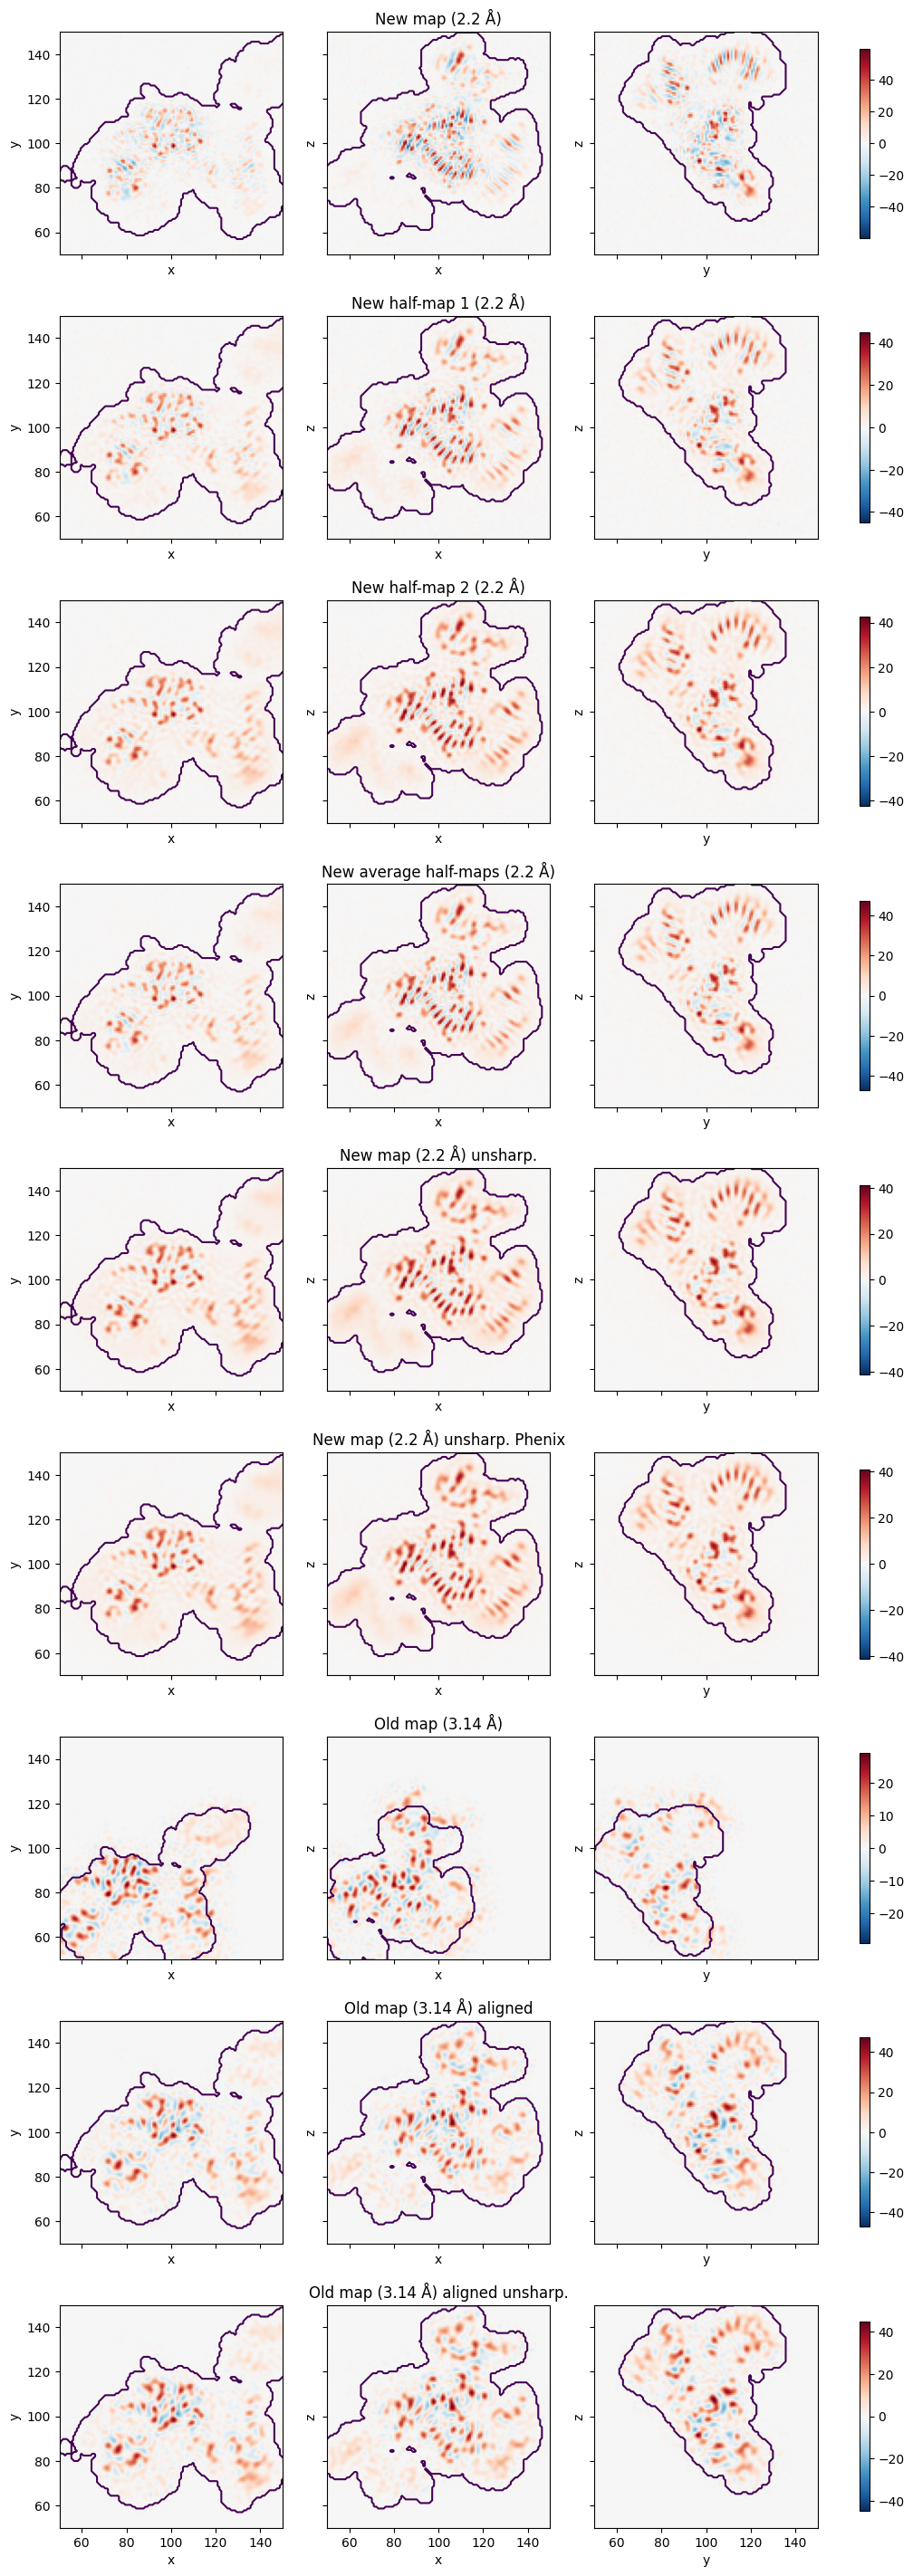

In [9]:
fig, axarr = plt.subplots(
    ncols=3, nrows=len(maps), sharex=True, sharey=True, figsize=(12, len(maps) * 4)
)

for i, plane in enumerate(("xy", "xz", "yz")):
    for v, ax in zip(maps.values(), axarr[:, i]):
        norm = CenteredNorm()
        _ = plot_map_slice(
            v / v.grid.std(), "imshow", ax=ax, plane=plane, norm=norm, cmap="RdBu_r"
        )
        _ = plot_map_slice(
            Grid(new_cc_mask, edges=v.edges),
            "contour",
            ax=ax,
            plane=plane,
            levels=[0.5],
        )

plt.gca().set_xlim(50, 150)
plt.gca().set_ylim(50, 150)
for k, ax in zip(maps.keys(), axarr[:, 1]):
    ax.set_title(k)
for axes in axarr:
    plt.colorbar(axes[0].images[0], ax=axes, shrink=0.8, fraction=0.05, aspect=20)

### Comparison between half-maps

In [10]:
import pandas as pd
from scipy.stats import linregress
from tqdm import tqdm
import itertools
# Mutual information
import infomeasure as im

def mutual_info(x, y, n_subsamples=None):
    if n_subsamples is not None:
        inds = np.random.choice(len(x), size=n_subsamples, replace=False)
        x = x[inds]
        y = y[inds]
    # Whiten data 
    x = (x - np.mean(x)) / np.std(x)
    y = (y - np.mean(y)) / np.std(y)
    return im.mutual_information(x, y, approach="metric")
    

results = []
for (ki, mapi), (kj, mapj) in tqdm(itertools.product(maps.items(), repeat=2)):
    results.append({
        'Map 1': ki,
        'Map 2': kj,
        'CC': linregress(mapi.grid[new_cc_mask], mapj.grid[new_cc_mask]).rvalue,
        'MI': mutual_info(mapi.grid[new_cc_mask], mapj.grid[new_cc_mask], n_subsamples=10000) if ki != kj else np.nan,
    })

81it [00:34,  2.33it/s]


In [11]:
results = pd.DataFrame(results)
results.pivot(index=['Map 1'], columns=['Map 2'])['CC'].sort_index().style.background_gradient(vmin=0, vmax=1, cmap="Reds").format(precision=2)

Map 2,New average half-maps (2.2 Å),New half-map 1 (2.2 Å),New half-map 2 (2.2 Å),New map (2.2 Å),New map (2.2 Å) unsharp.,New map (2.2 Å) unsharp. Phenix,Old map (3.14 Å),Old map (3.14 Å) aligned,Old map (3.14 Å) aligned unsharp.
Map 1,,,,,,,,,
New average half-maps (2.2 Å),1.00,0.99,0.99,0.88,0.98,0.98,0.03,0.68,0.69
New half-map 1 (2.2 Å),0.99,1.00,0.95,0.92,0.95,0.94,0.03,0.64,0.64
New half-map 2 (2.2 Å),0.99,0.95,1.00,0.83,0.99,0.99,0.03,0.71,0.72
New map (2.2 Å),0.88,0.92,0.83,1.00,0.77,0.77,0.01,0.43,0.41
New map (2.2 Å) unsharp.,0.98,0.95,0.99,0.77,1.00,1.00,0.04,0.73,0.75
New map (2.2 Å) unsharp. Phenix,0.98,0.94,0.99,0.77,1.00,1.00,0.04,0.73,0.75
Old map (3.14 Å),0.03,0.03,0.03,0.01,0.04,0.04,1.00,0.02,0.02
Old map (3.14 Å) aligned,0.68,0.64,0.71,0.43,0.73,0.73,0.02,1.00,1.00
Old map (3.14 Å) aligned unsharp.,0.69,0.64,0.72,0.41,0.75,0.75,0.02,1.00,1.00


In [12]:
results.pivot(index=['Map 1'], columns=['Map 2'])['MI'].sort_index().style.background_gradient(vmin=0, vmax=results['MI'].max(), cmap="Reds").format(precision=2)

Map 2,New average half-maps (2.2 Å),New half-map 1 (2.2 Å),New half-map 2 (2.2 Å),New map (2.2 Å),New map (2.2 Å) unsharp.,New map (2.2 Å) unsharp. Phenix,Old map (3.14 Å),Old map (3.14 Å) aligned,Old map (3.14 Å) aligned unsharp.
Map 1,,,,,,,,,
New average half-maps (2.2 Å),nan,1.49,1.50,0.80,1.62,1.58,0.02,0.28,0.30
New half-map 1 (2.2 Å),1.50,nan,0.85,0.80,1.00,0.96,0.01,0.25,0.27
New half-map 2 (2.2 Å),1.49,0.86,nan,0.57,1.55,1.51,0.02,0.29,0.31
New map (2.2 Å),0.79,0.79,0.57,nan,0.51,0.49,0.03,0.16,0.17
New map (2.2 Å) unsharp.,1.60,0.97,1.52,0.49,nan,4.32,0.02,0.31,0.34
New map (2.2 Å) unsharp. Phenix,1.57,0.97,1.54,0.47,4.31,nan,0.02,0.31,0.34
Old map (3.14 Å),0.01,0.02,0.01,0.02,0.01,0.02,nan,0.01,0.01
Old map (3.14 Å) aligned,0.29,0.25,0.30,0.16,0.31,0.30,0.02,nan,2.49
Old map (3.14 Å) aligned unsharp.,0.30,0.25,0.30,0.16,0.35,0.33,0.01,2.47,nan


In [ ]:
# We can also do Quantile transformation
def quantilized_cross_correlation(x, y, x_bins=100, y_bins=100):
    p, x_bins = np.histogram(x, bins=x_bins, density=True)
    q, y_bins = np.histogram(y, bins=y_bins, density=True)
    qnorm = QuantileTransformation(
        p, q, x_range=edges_to_range(x_bins), y_range=edges_to_range(y_bins)
    )
    return linregress(x, qnorm(y)).rvalue

In [ ]:
df = pd.DataFrame(
    {
        ki: {
            kj: quantilized_cross_correlation(
                mapi.grid[new_cc_mask], mapj.grid[new_cc_mask]
            )
            for kj, mapj in maps.items()
        }
        for ki, mapi in maps.items()
    }
)
df.style.background_gradient(vmin=0, vmax=1, cmap="Reds").format(precision=2)

,New map (2.2 Å),New half-map 1 (2.2 Å),New half-map 2 (2.2 Å),New average half-maps (2.2 Å),New map (2.2 Å) unsharp.,New map (2.2 Å) unsharp. Phenix,Old map (3.14 Å),Old map (3.14 Å) aligned,Old map (3.14 Å) aligned unsharp.
New map (2.2 Å),1.00,0.94,0.88,0.92,0.85,0.85,0.02,0.46,0.45
New half-map 1 (2.2 Å),0.94,1.00,0.96,0.99,0.96,0.96,0.02,0.63,0.64
New half-map 2 (2.2 Å),0.87,0.96,1.00,0.99,0.99,0.99,0.03,0.69,0.71
New average half-maps (2.2 Å),0.92,0.99,0.99,1.00,0.99,0.99,0.03,0.67,0.68
New map (2.2 Å) unsharp.,0.82,0.96,0.99,0.98,1.00,1.00,0.04,0.72,0.74
New map (2.2 Å) unsharp. Phenix,0.81,0.96,0.99,0.98,1.00,1.00,0.04,0.72,0.74
Old map (3.14 Å),0.01,0.03,0.05,0.04,0.06,0.06,1.00,0.02,0.03
Old map (3.14 Å) aligned,0.43,0.66,0.74,0.71,0.77,0.77,0.02,1.00,1.00
Old map (3.14 Å) aligned unsharp.,0.41,0.66,0.74,0.71,0.78,0.78,0.02,1.00,1.00


### Compare simulations with maps

In [13]:
masks = {
    'RNA-Shell': indices_to_mask(voxels_around(new_ag, 6, new_map.grid_params), new_map.grid_params),
    'RNA': indices_to_mask(voxels_around(new_ag, 1.8, new_map.grid_params), new_map.grid_params),
    'Phosphates': indices_to_mask(voxels_around(new_ag.select_atoms('name P'), 6, new_map.grid_params), new_map.grid_params)
}

masks['Shell'] = masks['RNA-Shell'] & ~masks['RNA']
masks['Phosphates-Shell'] = masks['Phosphates'] & ~masks['RNA']

/tmp/ipykernel_324095/3241085374.py:32: UserWarning: The following kwargs were not used by contour: 'lw'
  out = func(grid.grid[s].T, origin="lower", extent=extent, **kwargs)


(50.0, 150.0)

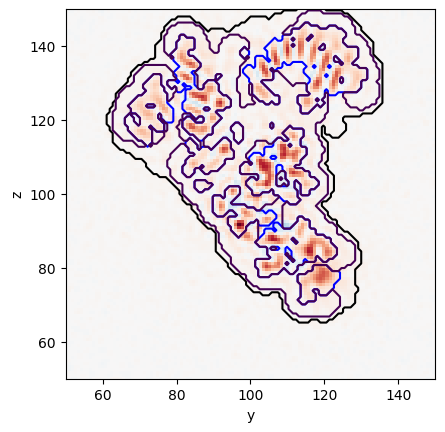

In [14]:
plot_map_slice(maps['New average half-maps (2.2 Å)'] / maps['New average half-maps (2.2 Å)'].grid.std(), "imshow", plane="yz", cmap="RdBu_r", norm=CenteredNorm())
plot_map_slice(
    Grid(masks['RNA-Shell'], edges=new_map.edges),
    "contour",
    plane="yz",
    levels=[0.5],
    colors='black',
    lw=0.5,
)
plot_map_slice(
    Grid(masks['RNA'], edges=new_map.edges),
    "contour",
    plane="yz",
    levels=[0.5],
    colors='blue',
    lw=0.5,
)
plot_map_slice(
    Grid(masks['Phosphates-Shell'], edges=new_map.edges),
    "contour",
    plane="yz",
    levels=[0.5],
)
plt.xlim(50, 150)
plt.ylim(50, 150)

In [15]:
from mg_sampling.density.grid import SparseGrid
# Replex

path = PROJECT_DIR / "density"

data = []
for filename in path.glob("*/*.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    data.append(
        dict(
            sim=filename.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=SparseGrid.load(filename).to_dense(),
            weight=weight,
        )
    )
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby("sim")["weight"].transform("sum")

In [17]:
import itertools
import functools
from mg_sampling.tools import bayesian_bootstrap
from tqdm import tqdm

results = []


def weighted_pearson_correlation(x, y, weights=None):
    return linregress(np.average(x, weights=weights), y).rvalue

def weighted_mutual_info(x, y, weights=None, n_subsamples=None):
    return mutual_info(np.average(x, weights=weights), y, n_subsamples=n_subsamples)


for k, mask in masks.items():
    for (simA, groupA), (simB, groupB) in tqdm(itertools.product(
        gen_maps.groupby("sim")[["map", "weight"]], repeat=2
    )):
        mapsA = groupA["map"].apply(lambda x: x.grid[mask]).to_numpy()
        mapsB = groupB["map"].apply(lambda x: x.grid[mask]).to_numpy()
        weightsA = groupA["weight"].to_numpy()
        weightsB = groupB["weight"].to_numpy()
        mapA = np.average(mapsA, weights=weightsA)
        mapB = np.average(mapsB, weights=weightsB)
        cc = linregress(
            mapA,
            mapB,
        ).rvalue

        cc_low, cc_high = bayesian_bootstrap(
            mapsA,
            functools.partial(weighted_pearson_correlation, y=mapB),
            weights=weightsA,
            n_resamples=50,
        ).confidence_interval

        results.append(
            {
                "simA": simA,
                "simB": simB,
                "mask": k,
                "cc": cc,
                "cc_low": cc_low,
                "cc_high": cc_high,
            }
        )


1it [00:01,  1.13s/it]

49it [00:51,  1.05s/it]
49it [00:20,  2.35it/s]
49it [00:34,  1.40it/s]
49it [00:38,  1.28it/s]
49it [00:26,  1.86it/s]


In [18]:
sim_labels = {
    "plain_md_7ez0_mMg_tip3p": "μMg (MD)",
    "plain_md_7ez0_nMg_tip3p": "nMg (MD)",
    "plain_md_7ez0_nMg_tip3p_soft": "nMg (MD-soft)",
    "plain_md_7ez0_noion_nMg_tip3p": "nMg (MD-denovo)",
    "plain_md_7ez0_nomg_mMg_tip3p": "no-Mg (MD)",
    "replex_7ez0_mMg_tip3p": "μMg (REx)",
    "replex_7ez0_noion_mMg_tip3p": "μMg (REx-denovo)",
}


In [19]:
sim_sim_results = pd.DataFrame(results).set_index(["simA", "simB", "mask"]).rename(index=sim_labels)

In [20]:
sim_sim_results.loc[:, :, "Shell"].unstack('simB').swaplevel(axis='columns').sort_index(axis='columns').style.background_gradient(vmin=0, vmax=1, cmap="Reds").format(precision=2)

In [54]:
sim_sim_results.loc[:, :, "Phosphates-Shell"].unstack('simB').swaplevel(axis='columns').sort_index(axis='columns').style.background_gradient(vmin=0, vmax=1, cmap="Reds").format(precision=2)

In [21]:
ref_maps = pd.Series(maps, name='map').rename_axis('desc').reset_index()

In [22]:
ref_maps

,desc,map
0,New map (2.2 Å),<<class 'mg_sampling.density.grid.Grid'> with ...
1,New half-map 1 (2.2 Å),<<class 'mg_sampling.density.grid.Grid'> with ...
2,New half-map 2 (2.2 Å),<<class 'mg_sampling.density.grid.Grid'> with ...
3,New average half-maps (2.2 Å),<<class 'mg_sampling.density.grid.Grid'> with ...
4,New map (2.2 Å) unsharp.,<<class 'mg_sampling.density.grid.Grid'> with ...
5,New map (2.2 Å) unsharp. Phenix,<<class 'mg_sampling.density.grid.Grid'> with ...
6,Old map (3.14 Å),<<class 'mg_sampling.density.grid.Grid'> with ...
7,Old map (3.14 Å) aligned,<<class 'mg_sampling.density.grid.Grid'> with ...
8,Old map (3.14 Å) aligned unsharp.,<<class 'mg_sampling.density.grid.Grid'> with ...


In [24]:
from mg_sampling.tools import bayesian_bootstrap
from mg_sampling.tools import bootstrap

results = []

for k, mask in masks.items():
    for sim, group in tqdm(gen_maps.groupby("sim")[["map", "weight"]]):
        for _, ref, refmap in ref_maps.itertuples():
            mapsA = group["map"].apply(lambda x: x.grid[mask]).to_numpy()
            weightsA = group["weight"].to_numpy()
            mapA = np.average(mapsA, weights=weightsA)
            mapB = refmap.grid[mask]
            cc = linregress(
                mapA,
                mapB,
            ).rvalue
            # mi = mutual_info(
            #     mapA,
            #     mapB,
            #     n_subsamples=10000,
            # )
            cc_low, cc_high = bootstrap(
                mapsA,
                functools.partial(weighted_pearson_correlation, y=mapB),
                weights=weightsA,
                n_resamples=100,
            ).confidence_interval
            # mi_stderr = bootstrap(
            #     mapsA,
            #     functools.partial(weighted_mutual_info, y=mapB, n_subsamples=10000),
            #     weights=weightsA,
            #     n_resamples=5,
            # ).standard_error

            results.append(
                {
                    "sim": sim,
                    "ref": ref,
                    "mask": k,
                    "cc": cc,
                    "cc_low": cc_low,
                    "cc_high": cc_high,
                    # "mi": mi,
                    # "mi_stderr": mi_stderr,
                }
            )

100%|██████████| 7/7 [00:42<00:00,  6.05s/it]


In [25]:
pd.DataFrame(results).query("mask == 'Shell' and ref == 'New half-map 1 (2.2 Å)'").sort_values("cc").style.background_gradient(axis=None)

,sim,ref,mask,cc,cc_low,cc_high
208,plain_md_7ez0_nMg_tip3p_soft,New half-map 1 (2.2 Å),Shell,0.019239,0.007415,0.027139
217,plain_md_7ez0_noion_nMg_tip3p,New half-map 1 (2.2 Å),Shell,0.158409,0.046743,0.211767
226,plain_md_7ez0_nomg_mMg_tip3p,New half-map 1 (2.2 Å),Shell,0.207871,0.198954,0.212432
244,replex_7ez0_noion_mMg_tip3p,New half-map 1 (2.2 Å),Shell,0.229183,0.222077,0.230796
190,plain_md_7ez0_mMg_tip3p,New half-map 1 (2.2 Å),Shell,0.241758,0.234361,0.242995
235,replex_7ez0_mMg_tip3p,New half-map 1 (2.2 Å),Shell,0.244046,0.234593,0.242703
199,plain_md_7ez0_nMg_tip3p,New half-map 1 (2.2 Å),Shell,0.246857,0.235681,0.246926


In [26]:
pd.DataFrame(results).query("mask == 'Shell' and ref == 'New half-map 2 (2.2 Å)'").sort_values("cc").style.background_gradient(axis=None)

,sim,ref,mask,cc,cc_low,cc_high
209,plain_md_7ez0_nMg_tip3p_soft,New half-map 2 (2.2 Å),Shell,0.171038,0.149515,0.175954
227,plain_md_7ez0_nomg_mMg_tip3p,New half-map 2 (2.2 Å),Shell,0.269367,0.258341,0.273006
218,plain_md_7ez0_noion_nMg_tip3p,New half-map 2 (2.2 Å),Shell,0.285296,0.185815,0.302365
245,replex_7ez0_noion_mMg_tip3p,New half-map 2 (2.2 Å),Shell,0.291156,0.281879,0.291956
191,plain_md_7ez0_mMg_tip3p,New half-map 2 (2.2 Å),Shell,0.302968,0.289190,0.303524
236,replex_7ez0_mMg_tip3p,New half-map 2 (2.2 Å),Shell,0.306018,0.295583,0.304424
200,plain_md_7ez0_nMg_tip3p,New half-map 2 (2.2 Å),Shell,0.308516,0.297564,0.307635


In [ ]:
u = structs['7ez0 ']

8307

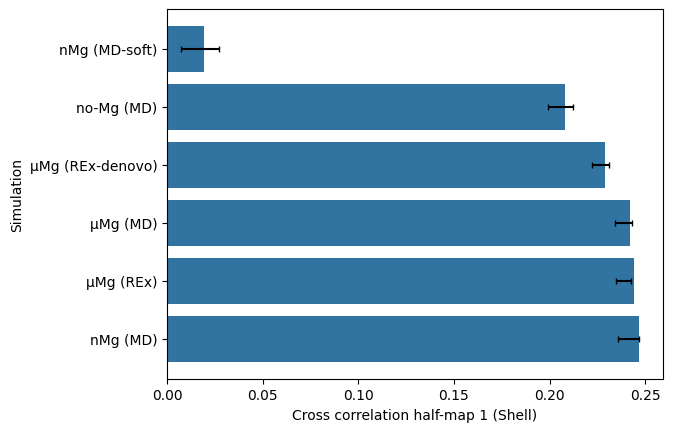

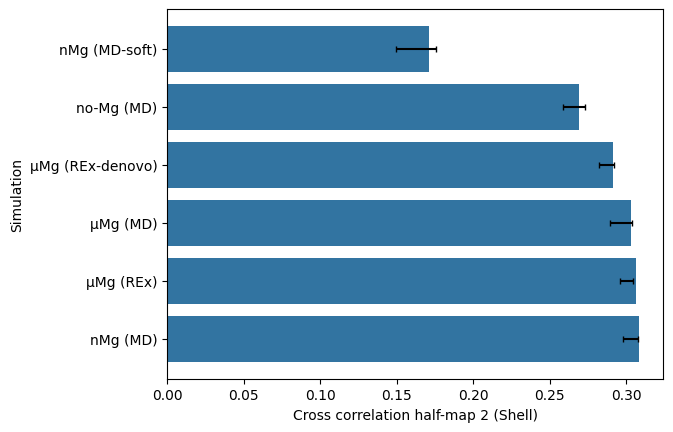

In [27]:
import seaborn as sns

for i in range(1,3):
    results = pd.DataFrame(results).query("sim != 'plain_md_7ez0_noion_nMg_tip3p'")
    results['sim_label'] = results['sim'].map(sim_labels)
    df = results.query(f"mask == 'Shell' and ref == 'New half-map {i} (2.2 Å)'").sort_values("cc")

    ax = sns.barplot(
        df,
        y='sim_label',
        x='cc',
    )

    y_coords = np.arange(len(df))

    x_data = df["cc"].clip(df["cc_low"], df["cc_high"])
    x_err = x_data - df["cc_low"], df["cc_high"] - x_data
    ax.errorbar(
        x=x_data,
        y=y_coords,
        xerr=x_err,
        color='black',
        capsize=2,
        linestyle='none',
    )

    plt.xlabel(f"Cross correlation half-map {i} (Shell)")
    plt.ylabel("Simulation")
    plt.show()

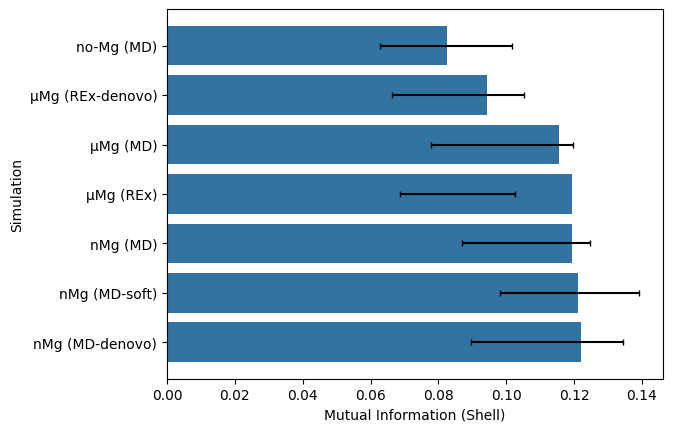

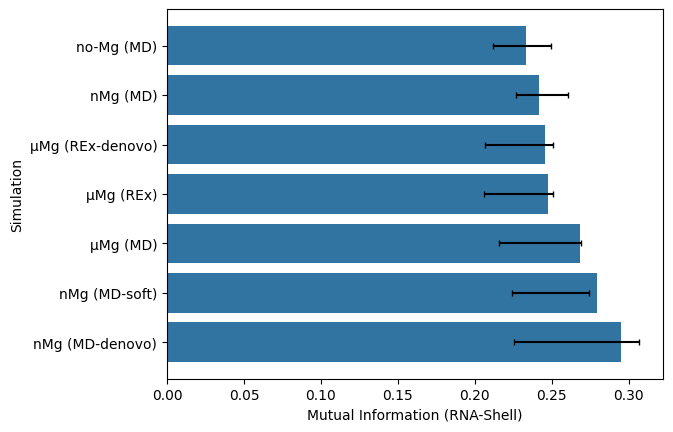

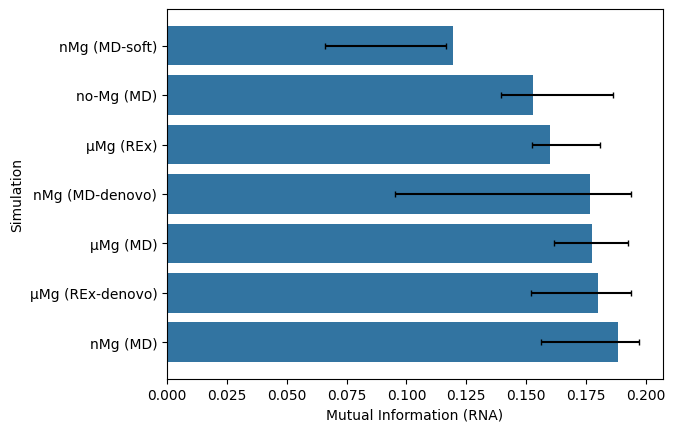

In [116]:
import seaborn as sns

for mask_label in ('Shell', 'RNA-Shell', 'RNA'):
    results = pd.DataFrame(results)
    results['sim_label'] = results['sim'].map(sim_labels)
    df = results.query("mask == @mask_label and ref == 'New average half-maps (2.2 Å)'").sort_values("mi")

    ax = sns.barplot(
        df,
        y='sim_label',
        x='mi',
    )

    y_coords = np.arange(len(df))

    x_data = df["mi"].clip(df["mi_low"], df["mi_high"])
    x_err = x_data - df["mi_low"], df["mi_high"] - x_data
    ax.errorbar(
        x=x_data,
        y=y_coords,
        xerr=x_err,
        color='black',
        capsize=2,
        linestyle='none',
    )

    plt.xlabel(f"Mutual Information ({mask_label})")
    plt.ylabel("Simulation")
    plt.show()

(0.4, 0.6793836259721551)

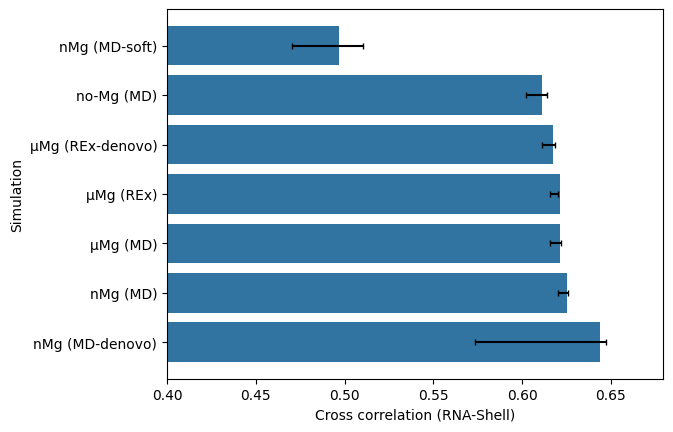

In [109]:
import seaborn as sns

results = pd.DataFrame(results)
results['sim_label'] = results['sim'].map(sim_labels)
df = results.query("mask == 'RNA-Shell' and ref == 'New average half-maps (2.2 Å)'").sort_values("cc")

ax = sns.barplot(
    df,
    y='sim_label',
    x='cc',
)

y_coords = np.arange(len(df))

x_data = df["cc"].clip(df["cc_low"], df["cc_high"])
x_err = x_data - df["cc_low"], df["cc_high"] - x_data
ax.errorbar(
    x=x_data,
    y=y_coords,
    xerr=x_err,
    color='black',
    capsize=2,
    linestyle='none',
)

plt.xlabel("Cross correlation (RNA-Shell)")
plt.ylabel("Simulation")
plt.xlim(0.4, None)